# Fashion-MNIST Variational Autoencoder

Assignment notebook adapted from David Foster, *Generative Deep Learning* (2nd ed.), O'Reilly, 2023, Chapter 3, and the companion notebook [vae_fashion.ipynb](https://github.com/davidADSP/Generative_Deep_Learning_2nd_Edition/blob/main/notebooks/03_vae/02_vae_fashion/vae_fashion.ipynb).

**Goals (rubric):** train a VAE with separately logged total / reconstruction / KL losses; ablate latent dimensions `{2, 8, 32}`; show prior samples and a class-colored latent scatter; interpret results via the ELBO.

Reusable code lives in `vae_fashion.py`. Full ablation training is also available via `python run_experiments.py`. This notebook loads the trained models and logged histories so it executes end-to-end without re-training (~5–6 minutes of CPU training already recorded in `artifacts/metrics.json`).


## 0. Setup

Seed, imports, and paths. Environment: TensorFlow 2.21 / Keras 3 on CPU (Apple Silicon).


In [1]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display
from tensorflow import keras

from vae_fashion import (
    BETA,
    CLASS_NAMES,
    IMAGE_SIZE,
    LATENT_DIMS,
    SEED,
    Sampling,
    VAE,
    encode_images,
    environment_info,
    load_fashion_mnist,
    plot_ablation_curves,
    plot_latent_scatter,
    plot_loss_curves,
    plot_prior_samples,
    plot_reconstructions_comparison,
    set_seed,
)

set_seed(SEED)
ROOT = Path(".").resolve()
ARTIFACTS = ROOT / "artifacts"
MODELS = ROOT / "models"

keras.utils.get_custom_objects()["Sampling"] = Sampling
keras.utils.get_custom_objects()["VAE"] = VAE

print(json.dumps(environment_info(), indent=2))


{
  "python": "3.13.0",
  "tensorflow": "2.21.0",
  "keras": "3.15.1",
  "numpy": "2.5.4",
  "devices": [
    "/physical_device:CPU:0"
  ],
  "seed": 42,
  "batch_size": 100,
  "epochs": 5,
  "beta": 500.0,
  "learning_rate": 0.0005,
  "image_size": 32,
  "latent_dims": [
    2,
    8,
    32
  ]
}


## 1. ELBO and the three logged losses

A VAE maximizes a lower bound on the data log-likelihood (the **ELBO**). With a Bernoulli decoder on pixels in $[0,1]$, the bound splits into:

1. **Reconstruction term:** expected log-likelihood $\mathbb{E}_{q_\phi(z|x)}[\log p_\theta(x|z)]$. Here that is a **binary cross-entropy** summed over pixels and scaled by `beta=500` (Foster Ch.3 convention), so the optimizer prioritizes sharp reconstructions over a tightly matched prior.
2. **KL term:** $D_{KL}\big(q_\phi(z|x)\,\|\,p(z)\big)$ with standard-normal prior $p(z)=\mathcal{N}(0,I)$. This pulls each approximate posterior toward the prior so the latent space stays continuous and samplable.

The training objective minimized here is

$$\mathcal{L} = \underbrace{\beta \cdot \mathrm{BCE}(x, \hat{x})}_{\text{reconstruction_loss}} + \underbrace{D_{KL}(q\|p)}_{\text{kl_loss}}, \qquad \text{loss} = \text{reconstruction_loss} + \text{kl_loss}.$$

All three scalars are tracked every epoch (train and validation).


## 2. Data

Fashion-MNIST, scaled to $[0,1]$, padded from 28×28 to 32×32, channel axis added.


(60000, 32, 32, 1) (10000, 32, 32, 1) 0.0 1.0


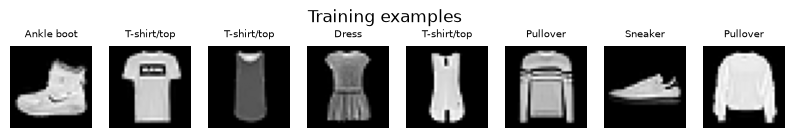

In [2]:
x_train, y_train, x_test, y_test = load_fashion_mnist()
print(x_train.shape, x_test.shape, x_train.min(), x_train.max())

fig, axes = plt.subplots(1, 8, figsize=(10, 1.6))
for i, ax in enumerate(axes):
    ax.imshow(x_train[i].squeeze(), cmap="gray")
    ax.set_title(CLASS_NAMES[int(y_train[i])], fontsize=7)
    ax.axis("off")
fig.suptitle("Training examples")
plt.show()


## 3. Model

Encoder: three stride-2 `Conv2D` blocks (32/64/128) → `Dense` heads for `z_mean`, `z_log_var` → `Sampling` (reparameterization). Decoder mirrors with `Conv2DTranspose` and a sigmoid output. The custom `VAE` logs the three ELBO terms in `train_step` / `test_step`.


In [3]:
# Load the three trained VAEs (and their encoder/decoder submodels).
vaes = {}
for dim in LATENT_DIMS:
    path = MODELS / f"vae_dim{dim}.keras"
    vaes[dim] = keras.models.load_model(
        path, custom_objects={"Sampling": Sampling, "VAE": VAE}
    )
    print(f"loaded {path.name}: latent_dim={dim}, beta={vaes[dim].beta}")

vaes[2].encoder.summary()


loaded vae_dim2.keras: latent_dim=2, beta=500.0
loaded vae_dim8.keras: latent_dim=8, beta=500.0
loaded vae_dim32.keras: latent_dim=32, beta=500.0


/Users/sydneysanders/Desktop/Projects/OnCode/vae-fashion/.venv/lib/python3.13/site-packages/keras/src/saving/saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'adam', because it has 42 variables whereas the saved optimizer has 2 variables. 
  saveable.load_own_variables(store)
/Users/sydneysanders/Desktop/Projects/OnCode/vae-fashion/.venv/lib/python3.13/site-packages/keras/src/saving/saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'adam_1', because it has 42 variables whereas the saved optimizer has 2 variables. 
  saveable.load_own_variables(store)
/Users/sydneysanders/Desktop/Projects/OnCode/vae-fashion/.venv/lib/python3.13/site-packages/keras/src/saving/saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'adam_2', because it has 42 variables whereas the saved optimizer has 2 variables. 
  saveable.load_own_variables(store)


Model: "encoder"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ encoder_input       │ (None, 32, 32, 1) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 16, 16,    │        320 │ encoder_input[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 8, 8, 64)  │     18,496 │ conv2d[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 4, 4, 128) │     73,856 │ conv2d_1[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten (Flatten)   │ (None, 2048)      │          0 │ conv2d_2[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z_mean (Dense)      │ (None, 2)         │      4,098 │ flatten[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z_log_var (Dense)   │ (None, 2)         │      4,098 │ flatten[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sampling (Sampling) │ (None, 2)         │          0 │ z_mean[0][0],     │
│                     │                   │            │ z_log_var[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 100,868 (394.02 KB)

 Trainable params: 100,868 (394.02 KB)

 Non-trainable params: 0 (0.00 B)

## 4. Logged losses (primary model, latent_dim=2)

Three separate curves: total loss, reconstruction loss, and KL.


,epoch,kl_loss,loss,reconstruction_loss,val_kl_loss,val_loss,val_reconstruction_loss
0,1,76.292046,162246.078125,162169.765625,40.942039,136757.671875,136716.687500
1,2,35.907242,134161.546875,134125.625000,31.836309,133310.156250,133278.296875
2,3,29.710375,132067.281250,132037.593750,27.237825,131946.296875,131919.015625
3,4,27.145153,130829.000000,130801.984375,25.126770,131245.125000,131219.984375
4,5,25.933418,129957.890625,129932.023438,23.976439,130784.367188,130760.320312


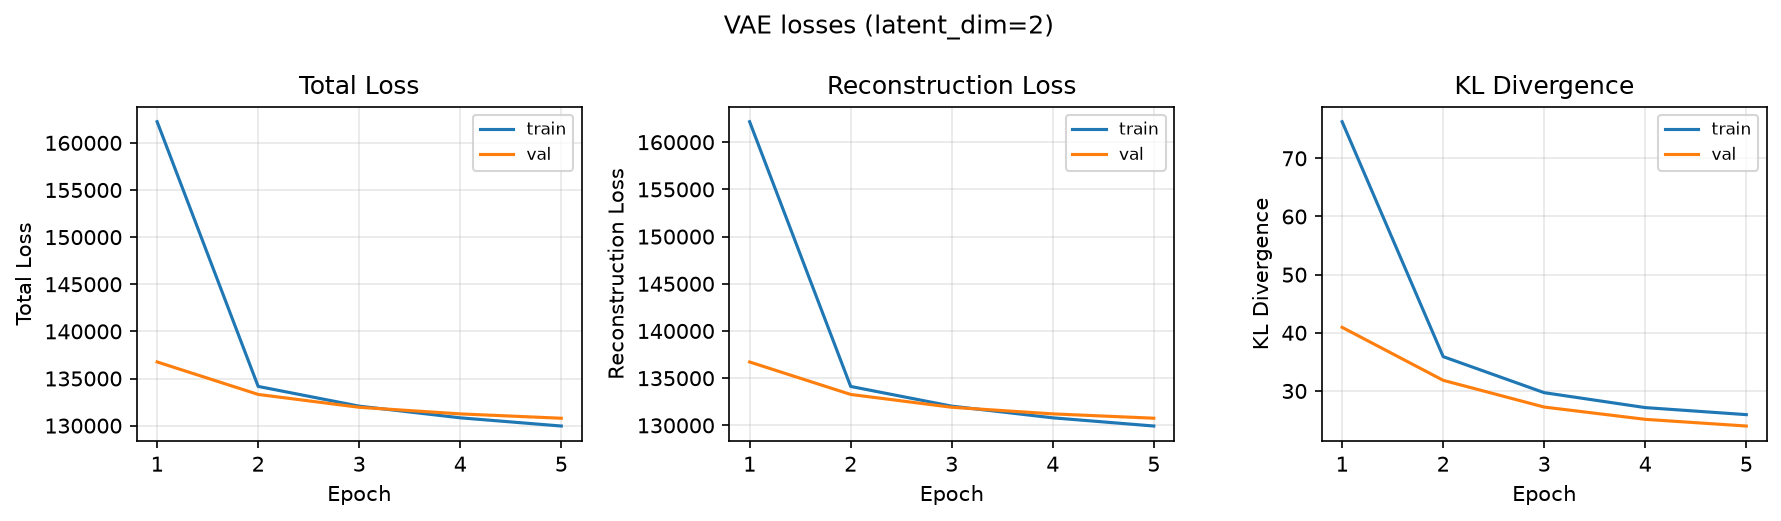

Final dim=2: loss=129957.9, recon=129932.0, kl=25.93


In [4]:
histories = {
    dim: pd.read_csv(ARTIFACTS / f"history_dim{dim}.csv") for dim in LATENT_DIMS
}
metrics = json.loads((ARTIFACTS / "metrics.json").read_text())

display(histories[2].tail())
plot_loss_curves(
    histories[2],
    ARTIFACTS / "loss_curves.png",
    title="VAE losses (latent_dim=2)",
)
display(Image(filename=str(ARTIFACTS / "loss_curves.png")))

run2 = metrics["runs"]["2"]
print(
    f"Final dim=2: loss={run2['final_loss']:.1f}, "
    f"recon={run2['final_reconstruction_loss']:.1f}, "
    f"kl={run2['final_kl_loss']:.2f}"
)


## 5. Latent-dimension ablation `{2, 8, 32}`

Same architecture, seed, epochs, and `beta`; only the bottleneck width changes. Larger latent dimension lowers reconstruction loss and raises KL (more capacity to encode class/structure, farther from a unit Gaussian in aggregate).


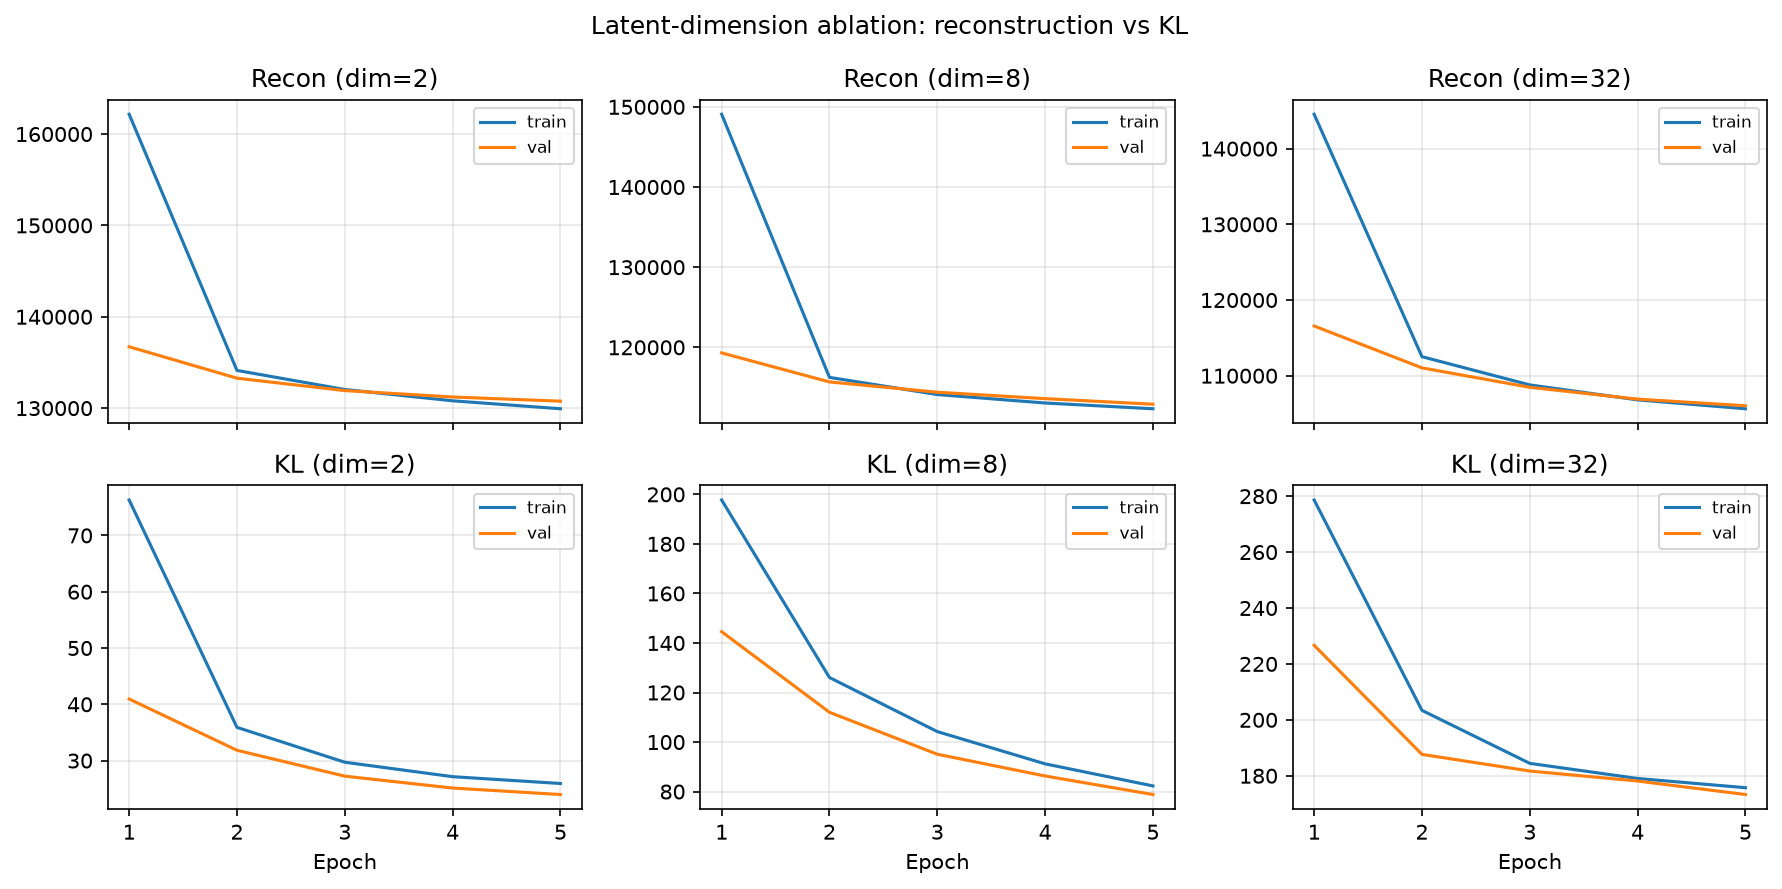

,latent_dim,final_loss,final_reconstruction_loss,final_kl_loss,final_val_loss,train_seconds
0,2,129957.89,129932.02,25.93,130784.37,106.94
1,8,112418.32,112335.98,82.29,112982.18,109.21
2,32,105810.34,105634.60,175.73,106203.77,114.16


In [5]:
plot_ablation_curves(histories, ARTIFACTS / "ablation_curves.png")
display(Image(filename=str(ARTIFACTS / "ablation_curves.png")))

summary_rows = []
for dim in LATENT_DIMS:
    r = metrics["runs"][str(dim)]
    summary_rows.append(
        {
            "latent_dim": dim,
            "final_loss": r["final_loss"],
            "final_reconstruction_loss": r["final_reconstruction_loss"],
            "final_kl_loss": r["final_kl_loss"],
            "final_val_loss": r["final_val_loss"],
            "train_seconds": r["train_seconds"],
        }
    )
summary = pd.DataFrame(summary_rows)
display(summary.round(2))


### Reconstructions side-by-side

Originals vs reconstructions for each latent width.


E0000 00:00:1793648063.854917  395502 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


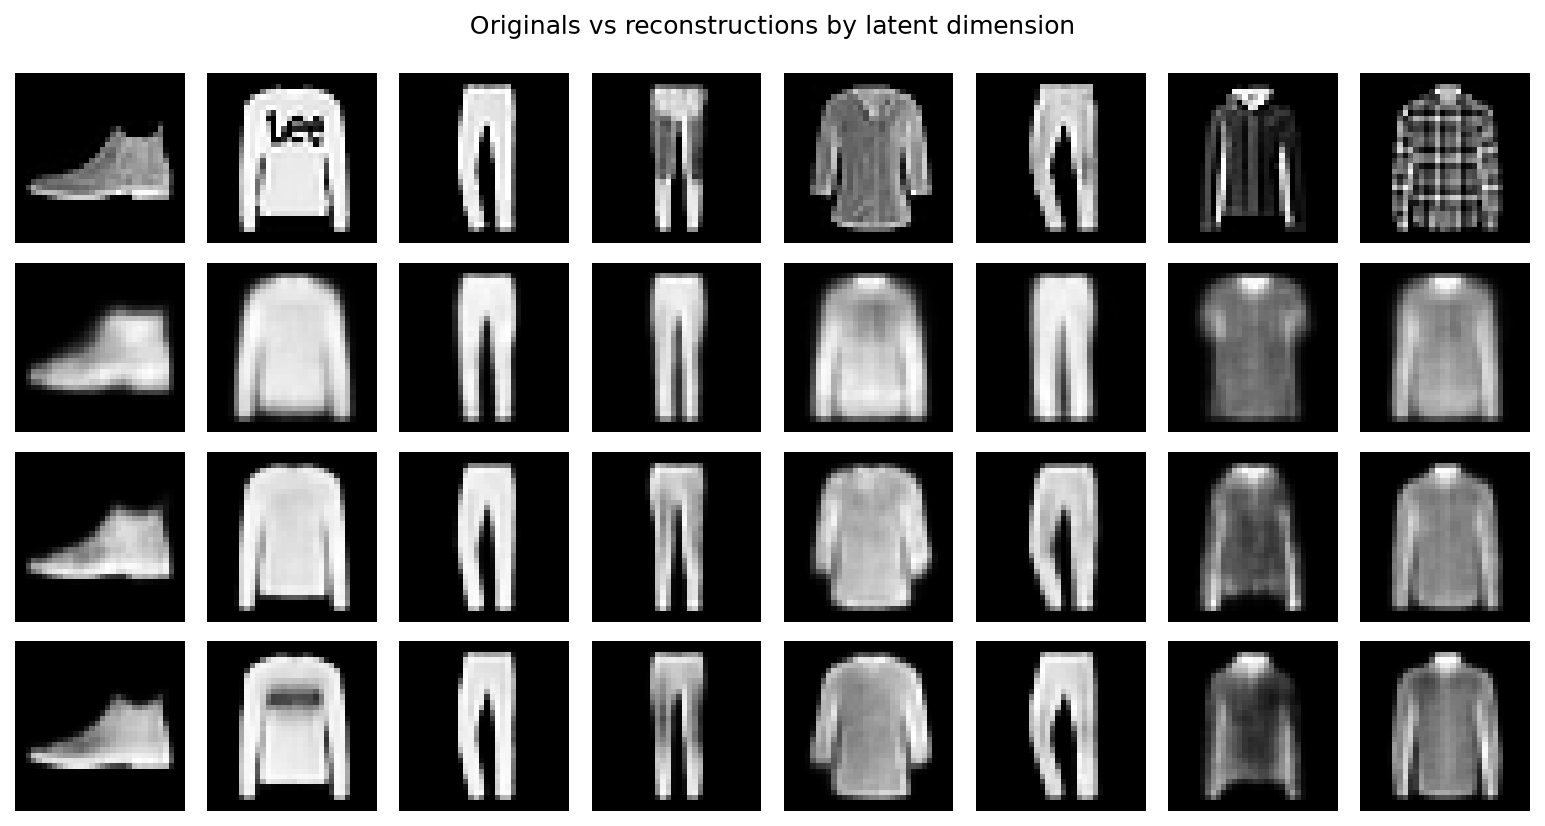

In [6]:
n_show = 8
n_encode = 5000
example_images = x_test[:n_encode]
example_labels = y_test[:n_encode]

reconstructions = {
    dim: vaes[dim].predict(example_images, verbose=0) for dim in LATENT_DIMS
}
plot_reconstructions_comparison(
    example_images,
    reconstructions,
    ARTIFACTS / "reconstructions.png",
    n=n_show,
)
display(Image(filename=str(ARTIFACTS / "reconstructions.png")))


## 6. Prior samples and latent scatter

Decode $z \sim \mathcal{N}(0,I)$. For `latent_dim=2` the scatter uses the raw axes; for 8 and 32 we PCA-project to 2D and label that honestly.


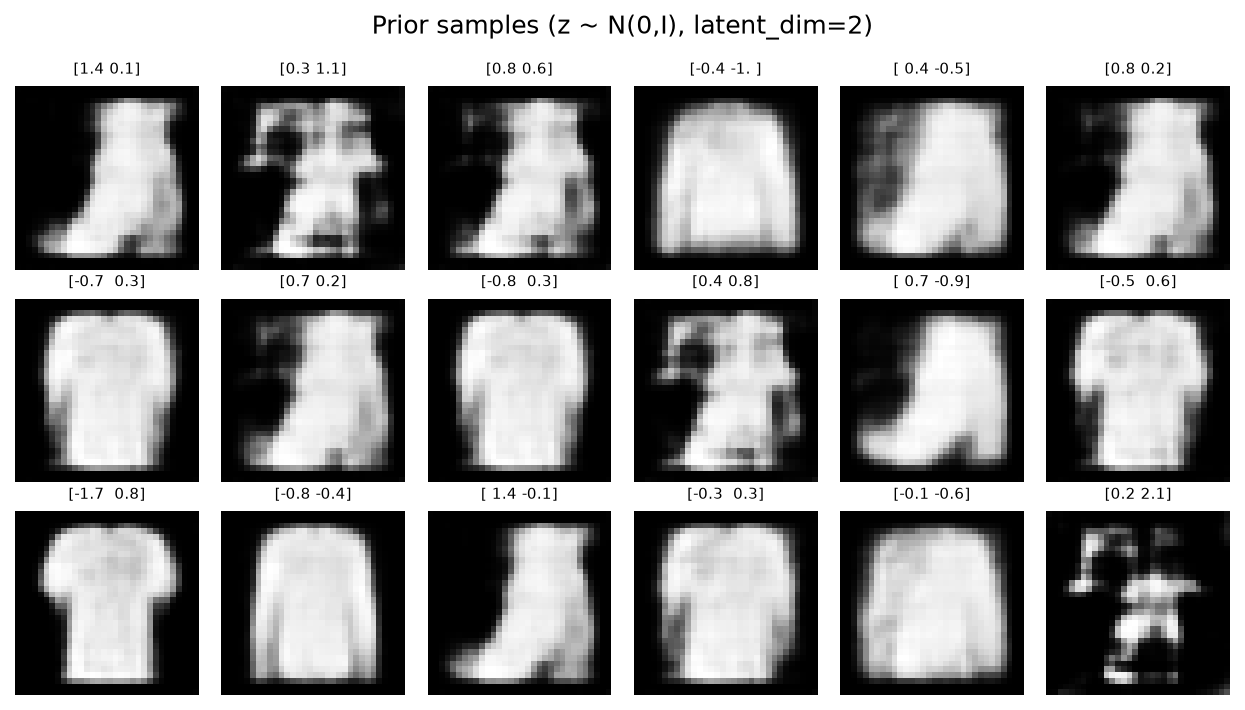

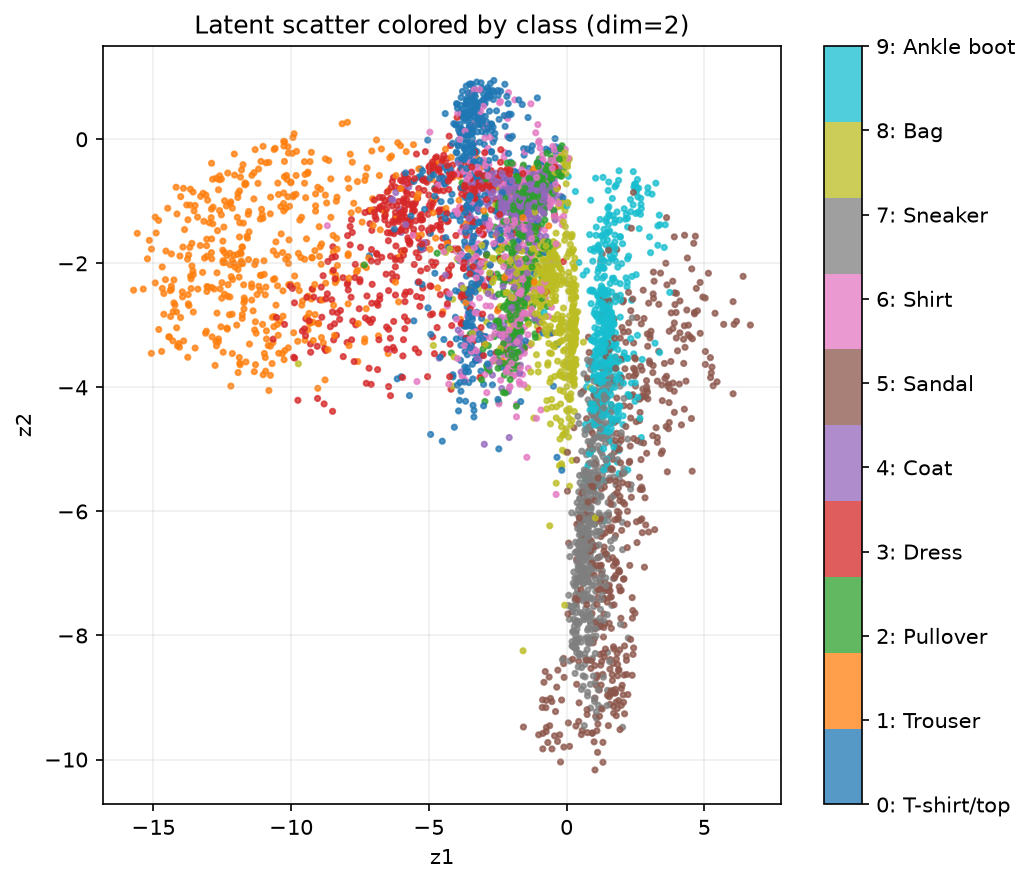

In [7]:
# Canonical prior samples + scatter for primary dim=2
plot_prior_samples(
    vaes[2].decoder,
    latent_dim=2,
    path=ARTIFACTS / "prior_samples.png",
    seed=SEED + 2,
)
display(Image(filename=str(ARTIFACTS / "prior_samples.png")))

z_mean_2, _, _ = encode_images(vaes[2].encoder, example_images)
plot_latent_scatter(
    z_mean_2,
    example_labels,
    path=ARTIFACTS / "latent_scatter.png",
    title="Latent scatter colored by class (dim=2)",
)
display(Image(filename=str(ARTIFACTS / "latent_scatter.png")))


E0000 00:00:1793648069.531349  395502 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


wrote prior_samples_dim2.png, latent_scatter_dim2.png


wrote prior_samples_dim8.png, latent_scatter_dim8.png


wrote prior_samples_dim32.png, latent_scatter_dim32.png


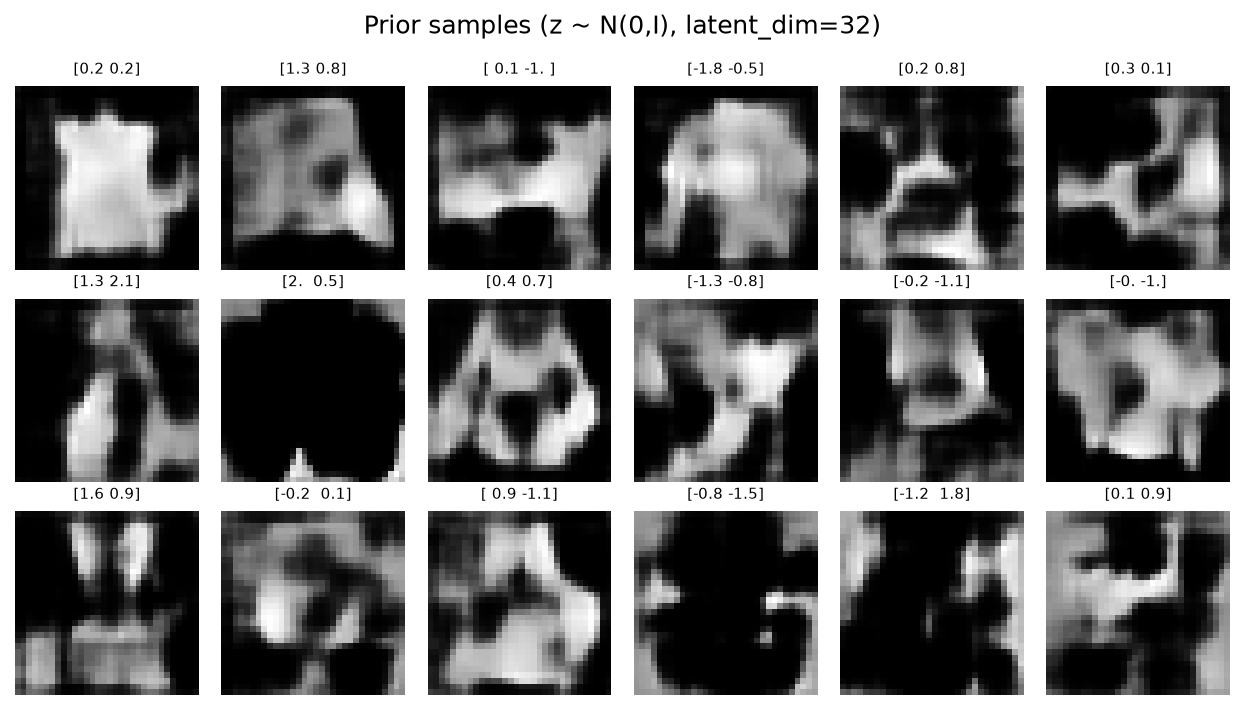

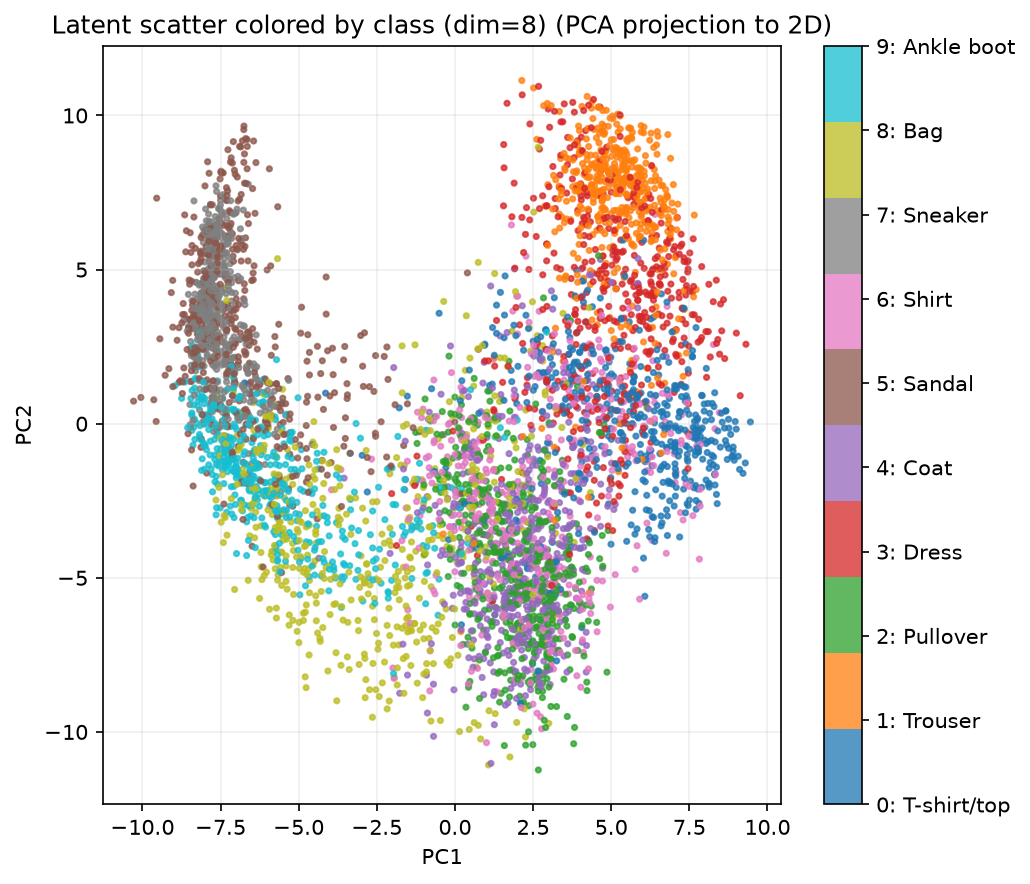

In [8]:
# Per-dim prior samples and scatters (also written under artifacts/)
for dim in LATENT_DIMS:
    plot_prior_samples(
        vaes[dim].decoder,
        latent_dim=dim,
        path=ARTIFACTS / f"prior_samples_dim{dim}.png",
        seed=SEED + dim,
    )
    z_mean, _, _ = encode_images(vaes[dim].encoder, example_images)
    plot_latent_scatter(
        z_mean,
        example_labels,
        path=ARTIFACTS / f"latent_scatter_dim{dim}.png",
        title=f"Latent scatter colored by class (dim={dim})",
    )
    print(f"wrote prior_samples_dim{dim}.png, latent_scatter_dim{dim}.png")

display(Image(filename=str(ARTIFACTS / "prior_samples_dim32.png")))
display(Image(filename=str(ARTIFACTS / "latent_scatter_dim8.png")))


## 7. Interpretation (from real metrics)

| dim | final recon | final KL | final loss | train (s) |
|----:|------------:|---------:|-----------:|----------:|
| 2 | 129932 | 25.9 | 129958 | ~107 |
| 8 | 112336 | 82.3 | 112418 | ~109 |
| 32 | 105635 | 175.7 | 105810 | ~114 |

- **Reconstruction vs KL trade-off:** With `beta=500`, reconstruction dominates the numeric loss. Raising latent dimension from 2→32 cuts recon loss by ~19% while KL grows ~7x. The approximate posteriors use more degrees of freedom and sit farther from the prior on average.
- **Dim-2 failure modes:** reconstructions are smeared silhouettes (lost logos/texture); footwear and upper-body classes overlap less cleanly than trousers, which form a distinct lobe in the 2D scatter. Prior samples are recognizable but ghostly; some draws look like class blends.
- **Dim-32:** sharper reconstructions and richer prior samples, but the PCA projection of the latent means is less readable as a simple 2D map: capacity moved into directions PCA compresses.
- **No KL collapse:** KL stays well above zero for all three runs (≈26 / 82 / 176), so the latent codes are informative rather than ignored.

See `WRITEUP.md` for the full prose write-up.


## 8. Reproducibility

- Seed `42`, `beta=500`, Adam `5e-4`, 5 epochs, batch size 100.
- Headless regenerate: `python run_experiments.py --latent-dims 2 8 32`
- Artifacts: `artifacts/metrics.json`, `history_dim{N}.csv`, figure PNGs; models under `models/`.
- Total ablation wall time on this machine: ~337 s (~5.6 min).


In [9]:
print("metrics.json top-level keys:", sorted(metrics.keys()))
print("per-dim history keys:", metrics["runs"]["2"]["history_keys"])
print("total_wall_seconds:", round(metrics["total_wall_seconds"], 1))
assert set(map(str, LATENT_DIMS)) <= set(metrics["runs"])
for dim in LATENT_DIMS:
    keys = set(metrics["runs"][str(dim)]["history_keys"])
    assert {"loss", "reconstruction_loss", "kl_loss"} <= keys
print("verification checks passed")


metrics.json top-level keys: ['actual_epochs', 'batch_size', 'beta', 'devices', 'epochs', 'image_size', 'keras', 'latent_dims', 'learning_rate', 'numpy', 'python', 'requested_epochs', 'runs', 'seed', 'smoke', 'tensorflow', 'total_wall_seconds']
per-dim history keys: ['epoch', 'kl_loss', 'loss', 'reconstruction_loss', 'val_kl_loss', 'val_loss', 'val_reconstruction_loss']
total_wall_seconds: 337.1
verification checks passed
